In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("EDAs", exist_ok=True)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

df = pd.read_csv("H2_cleaned.csv", dtype={"Agent": str})
df["ReservationStatusDate"] = pd.to_datetime(df["ReservationStatusDate"])
print(df.shape)

(48467, 30)


In [19]:
MONTHS = ["January", "February", "March", "April", "May", "June", "July","August", "September", "October", "November", "December"]

def feature_vs_cancel(col):
    counts = pd.crosstab(df[col], df["IsCanceled"]).rename(columns={0: "not canceled", 1: "canceled"})
    pct = counts.div(counts.sum(axis=1), axis=0).mul(100).round(1)
    print(pd.concat({"bookings": counts, "%": pct}, axis=1))

    x = np.arange(len(pct))
    w = 0.38
    fig, ax = plt.subplots(figsize=(max(6, 0.9 * len(pct) + 2), 4))
    b1 = ax.bar(x - w / 2, pct["not canceled"], w, color="#2a78d6", label="not canceled")
    b2 = ax.bar(x + w / 2, pct["canceled"], w, color="#eb6834", label="canceled")
    for bars, name in [(b1, "not canceled"), (b2, "canceled")]:
        for b, v, n in zip(bars, pct[name], counts[name]):
            ax.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.0f}%\n{n:,}", ha="center", fontsize=7.5)
    ax.set_xticks(x, pct.index.astype(str), rotation=45 if len(pct) > 6 else 0)
    ax.set_ylim(0, 135)
    ax.set_yticks(range(0, 101, 20))
    ax.set_ylabel("% of bookings")
    ax.set_title(f"{col}: canceled vs not canceled", loc="left", fontweight="bold")
    ax.legend(frameon=False, ncol=2, loc="upper left")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.savefig(f"EDAs/{col}.png", dpi=150)
    plt.show()

Leakage checks:

ReservationStatusDate

IsCanceled
0    100.0
1      7.3
dtype: float64


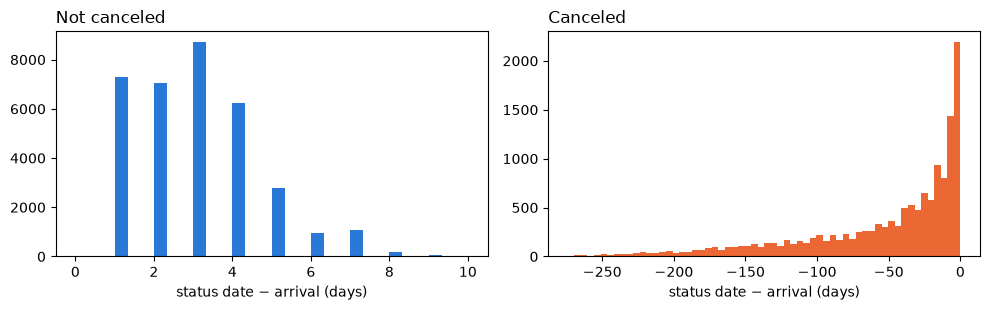

In [20]:
months = {m: i + 1 for i, m in enumerate(MONTHS)}
arrival = pd.to_datetime(dict(year=df["ArrivalDateYear"],month=df["ArrivalDateMonth"].map(months),day=df["ArrivalDateDayOfMonth"]))
days = (df["ReservationStatusDate"] - arrival).dt.days

print((days >= 0).groupby(df["IsCanceled"]).mean().mul(100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(days[df["IsCanceled"] == 0], bins=30, color="#2a78d6")
axes[0].set_title("Not canceled", loc="left")
axes[1].hist(days[df["IsCanceled"] == 1], bins=60, color="#eb6834")
axes[1].set_title("Canceled", loc="left")
for ax in axes:
    ax.set_xlabel("status date − arrival (days)")
plt.tight_layout()
plt.savefig("EDAs/status_date_minus_arrival.png", dpi=150)
plt.show()

status date is the checkout day always after arrival. Canceled is cancellation day always before arrival. Clear data leakage possible so we **Drop**

ReservationStatus

                      bookings                     %         
IsCanceled        not canceled canceled not canceled canceled
ReservationStatus                                            
Canceled                     0    13433          0.0    100.0
Check-Out                34393        0        100.0      0.0
No-Show                      0      641          0.0    100.0


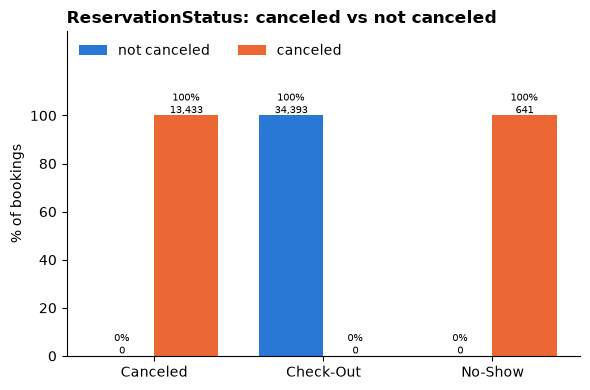

In [21]:
feature_vs_cancel("ReservationStatus")

checkout is 0% canceled, Canceled and No-Show are 100% **Drop**

In [22]:
df = df.drop(columns=["ReservationStatus", "ReservationStatusDate"])

RequiredCarParkingSpaces

                             bookings                     %         
IsCanceled               not canceled canceled not canceled canceled
RequiredCarParkingSpaces                                            
0                               32654    14074         69.9     30.1
1                                1737        0        100.0      0.0
3                                   2        0        100.0      0.0


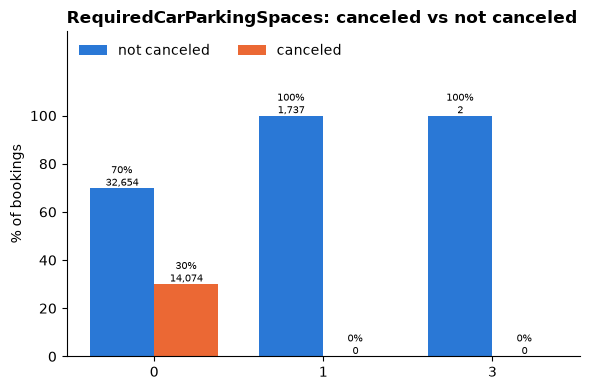

In [23]:
feature_vs_cancel("RequiredCarParkingSpaces")

No booking with parking space was canceled The value is most likely recorded when guest arrives so it is not known at booking time **Drop** 

In [24]:
df = df.drop(columns=["RequiredCarParkingSpaces"])

Features worth keeping

Correlation with IsCanceled

LeadTime                       0.201
TotalOfSpecialRequests        -0.168
BookingChanges                -0.120
PreviousCancellations          0.112
ADR                            0.105
Adults                         0.091
HasCompany                    -0.086
PreviousBookingsNotCanceled   -0.082
ArrivalDateYear                0.079
StaysInWeekNights              0.077
IsRepeatedGuest               -0.063
StaysInWeekendNights           0.035
DaysInWaitingList              0.028
Children                       0.028
Babies                        -0.020
ArrivalDateWeekNumber         -0.012
ArrivalDateDayOfMonth          0.002
Name: IsCanceled, dtype: float64


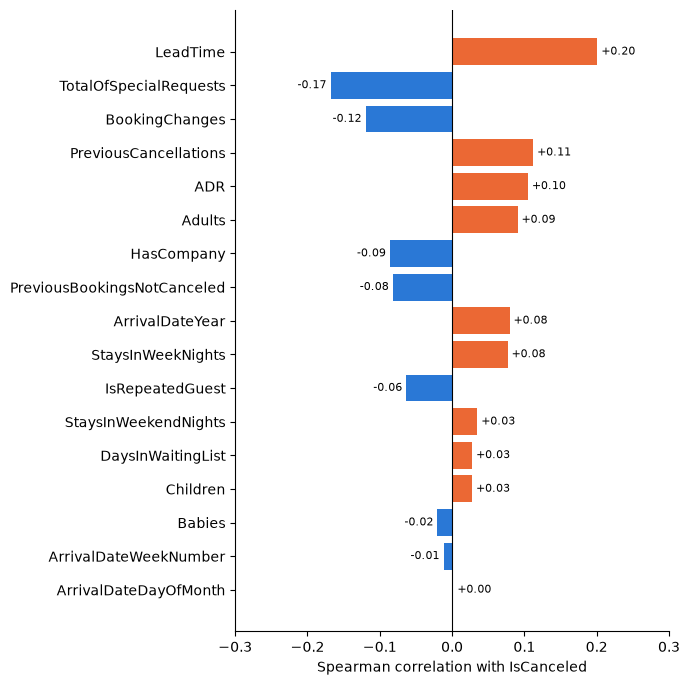

In [25]:
corr = df.select_dtypes("number").rank().corr()["IsCanceled"].drop("IsCanceled")
corr = corr.sort_values(key=abs, ascending=False)
print(corr.round(3))

plot = corr.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 0.35 * len(plot) + 1))
ax.barh(plot.index, plot.values, color=["#eb6834" if v > 0 else "#2a78d6" for v in plot.values])
for i, v in enumerate(plot.values):
    ax.text(v, i, f" {v:+.2f} ", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-0.3, 0.3)
ax.set_xlabel("Spearman correlation with IsCanceled")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("EDAs/correlation_with_iscanceled.png", dpi=150)
plt.show()

LeadTime has strongest positive coreletaion +0.20 where early bookings cancel more. Special requests is the strongest negative −0.17 where guests who make requests tend to come.

LeadTime

              count  mean   std  min   25%   50%    75%    max
IsCanceled                                                    
0           34393.0  62.8  64.7  0.0   9.0  40.0   99.0  274.0
1           14074.0  88.3  69.2  0.0  30.0  71.0  135.0  274.0
LeadTime
0-7        10.3
8-30       26.9
31-60      32.3
61-90      33.1
91-120     35.5
121-180    37.2
181-274    41.1
Name: IsCanceled, dtype: float64


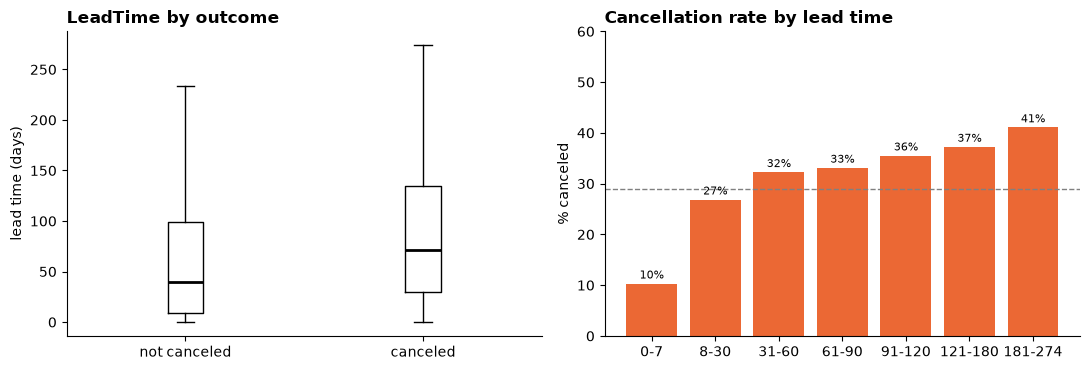

In [26]:
lt, target = df["LeadTime"], df["IsCanceled"]
print(df.groupby("IsCanceled")["LeadTime"].describe().round(1))

bands = pd.cut(lt, [-1, 7, 30, 60, 90, 120, 180, lt.max()],labels=["0-7", "8-30", "31-60", "61-90", "91-120", "121-180", f"181-{lt.max()}"])
rate = df.groupby(bands, observed=True)["IsCanceled"].mean() * 100
print(rate.round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].boxplot([lt[target == 0], lt[target == 1]], showfliers=False,medianprops=dict(color="black", lw=2))
axes[0].set_xticks([1, 2], ["not canceled", "canceled"])
axes[0].set_ylabel("lead time (days)")
axes[0].set_title("LeadTime by outcome", loc="left", fontweight="bold")

bars = axes[1].bar(rate.index.astype(str), rate.values, color="#eb6834")
axes[1].axhline(target.mean() * 100, color="gray", ls="--", lw=1)
for b, r in zip(bars, rate.values):
    axes[1].text(b.get_x() + b.get_width() / 2, r + 1, f"{r:.0f}%", ha="center", fontsize=8)
axes[1].set_ylim(0, 60)
axes[1].set_ylabel("% canceled")
axes[1].set_title("Cancellation rate by lead time", loc="left", fontweight="bold")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("EDAs/leadtime.png", dpi=150)
plt.show()

Canceled bookings were made earlier median 71 vs 40 days and cancellation rises from 10 to 41% as lead time growsit is known at booking so no leakage. **Keep**

DepositType

                bookings                     %         
IsCanceled  not canceled canceled not canceled canceled
DepositType                                            
No Deposit         34364    13559         71.7     28.3
Non Refund            24      507          4.5     95.5
Refundable             5        8         38.5     61.5


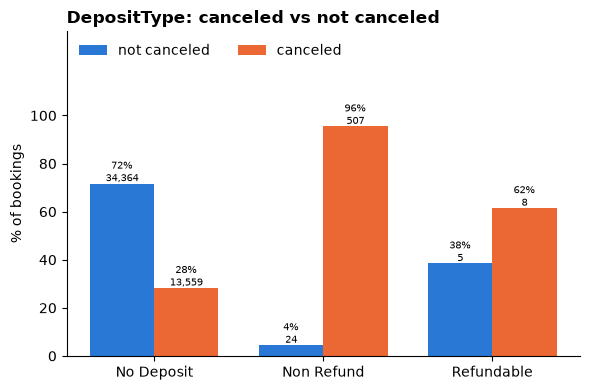

In [27]:
feature_vs_cancel("DepositType")

Non Refund bookings cancel 95% of the time and 28% for No Deposit Known at booking so **Keep**

Invalid rows

Undefined MarketSegment and DistributionChannel

                  bookings                     %         
IsCanceled    not canceled canceled not canceled canceled
MarketSegment                                            
Aviation               159       42         79.1     20.9
Complementary           20        2         90.9      9.1
Corporate             1923      252         88.4     11.6
Direct                4212      780         84.4     15.6
Groups                1496      576         72.2     27.8
Offline TA/TO         5514     1062         83.9     16.1
Online TA            21069    11358         65.0     35.0
Undefined                0        2          0.0    100.0


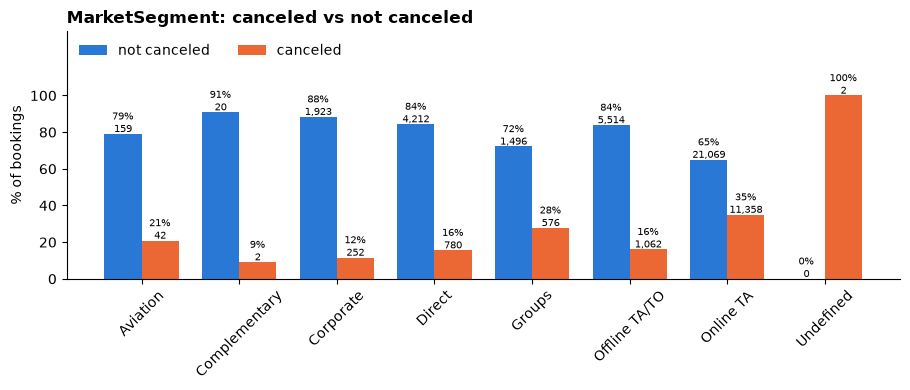

In [28]:
feature_vs_cancel("MarketSegment")

                        bookings                     %         
IsCanceled          not canceled canceled not canceled canceled
DistributionChannel                                            
Corporate                   2158      306         87.6     12.4
Direct                      4316      797         84.4     15.6
GDS                          140       31         81.9     18.1
TA/TO                      27779    12936         68.2     31.8
Undefined                      0        4          0.0    100.0


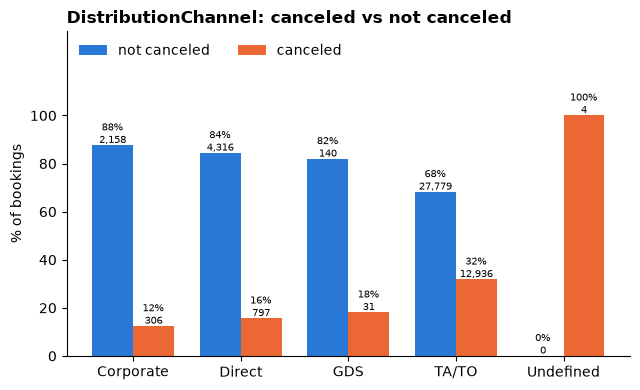

In [29]:
feature_vs_cancel("DistributionChannel")

Undefined is missing info **Drop the rows.**

In [30]:
before = len(df)
df = df[(df["MarketSegment"] != "Undefined") & (df["DistributionChannel"] != "Undefined")]
print("removed:", before - len(df))

removed: 4


Babies

               bookings                     %         
IsCanceled not canceled canceled not canceled canceled
Babies                                                
0                 34136    14015         70.9     29.1
1                   252       55         82.1     17.9
2                     3        0        100.0      0.0
9                     1        0        100.0      0.0
10                    1        0        100.0      0.0


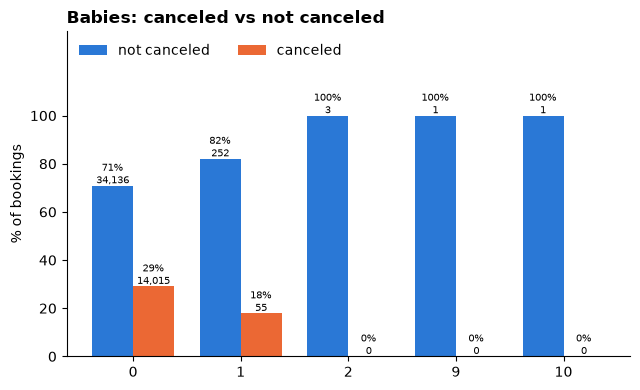

In [31]:
feature_vs_cancel("Babies")

In [32]:
before = len(df)
df = df[df["Babies"] <= 2]
print("removed:", before - len(df))

removed: 2


more drops

Agent

In [33]:
agents = df["Agent"].value_counts()
print("agent IDs:", len(agents))
print("IDs with < 50 bookings:", (agents < 50).sum())

agent IDs: 216
IDs with < 50 bookings: 169


hundreds of identified agent ids with very few bookings so **drop**

In [34]:
df = df.drop(columns=["Agent"], errors="ignore")
print(df.shape)

(48461, 26)
